# Assignment 4: Group Comparisons and Multivariate EDA

**Student names:** Alexeyenko Artyom and Akparov Dilshat  
**Student IDs:** 37463 and 37341  
**Course:** Exploratory Data Analysis  
**Assignment:** 4, Weeks 9–10  
**Dataset:** `BankChurners.csv`  
**Dataset source:** [Credit Card Customers on Kaggle](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers), as recorded in Assignment 1.

This notebook continues Assignments 1–3 using the same 10,127 customer records. We compare spending distributions, revisit the credit-limit–spending relationship within income groups, test income–attrition independence, and explore six numerical variables together. All principal analyses retain the full dataset. PCA is included as an exploratory summary.

## 0. Continuity with the completed assignments

| Previous work | Findings carried forward | Consequence for Assignment 4 |
|---|---|---|
| **Assignment 1 — initial EDA** | Existing customers outnumber attrited customers (8,500 versus 1,627). Attrited customers have lower transaction amounts and counts. Income has no simple monotonic relationship with attrition. | Report group sizes, within-group distributions, and percentages. Test the income–attrition question formally and distinguish statistical significance from association strength. |
| **Assignment 2 — distributions and outliers** | `Credit_Limit` and `Total_Trans_Amt` are right-skewed. Their upper IQR fences are \$23,836.25 and \$8,619.25. Three examined extreme customers were plausible and retained. Log credit limit reduced skewness. | Use medians and IQRs beside means and standard deviations; keep genuine extremes; check how monetary transformations affect PCA. |
| **Assignment 3 — bivariate EDA** | Transaction count–amount Pearson r ≈ 0.807; limit–amount r ≈ 0.172 but Spearman ρ ≈ 0.028. Limit–utilization is nonlinear. Card categories are extremely unequal in size. | Stratify the weak limit–amount relationship by income. Compare several variables jointly and interpret both coefficients and visible shapes. |

**Refinements after reviewing the earlier notebooks.** No technical `NaN` values does not mean all information is known: explicit `Unknown` categories remain in the file. Also, 508 records share the maximum credit limit of \$34,516. We describe this as a pile-up at the recorded maximum, consistent with a ceiling; this file alone does not establish the bank's actual limit-setting policy. Identifier and previous classifier-output columns do not represent customer measurements and are excluded from correlations and PCA.

The notebook is independent of the execution state of the earlier files: it reloads the original CSV, defines its own variables, and runs from top to bottom.

### 0.1 Setup and reproducibility

Run this notebook from the directory containing `BankChurners.csv`. Required packages are `numpy`, `pandas`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`, and `ipython`. If necessary, install them in the notebook's kernel environment with `%pip install numpy pandas matplotlib seaborn scipy scikit-learn ipython`, then restart the kernel and run all cells. Installation is deliberately separate from the analysis.

Tables and fitted calculations use **every customer**, with no sampling or imputation. Figure 2 uses a fixed random seed only to separate overlapping Platinum points horizontally. PCA uses a deterministic full SVD. Package versions and the source-file checksum are printed below so the executed result can be identified.

In [1]:
from pathlib import Path
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import scipy
from scipy.stats import chi2_contingency
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display

RANDOM_SEED = 42
ALPHA = 0.05
STATUS_ORDER = ['Attrited Customer', 'Existing Customer']
DRAW_ORDER = ['Existing Customer', 'Attrited Customer']
CARD_ORDER = ['Blue', 'Silver', 'Gold', 'Platinum']
INCOME_ORDER = [
    'Less than $40K', '$40K - $60K', '$60K - $80K',
    '$80K - $120K', '$120K +', 'Unknown'
]
STATUS_COLORS = {'Attrited Customer': '#bb504c', 'Existing Customer': '#3276a4'}
CARD_COLORS = ['#80add0', '#b2b7c0', '#e0bf67', '#bd9bc9']
usd_ticks = FuncFormatter(lambda value, position: f'{value:,.0f}')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 110, 'grid.alpha': 0.20,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlepad': 12, 'savefig.bbox': 'tight', 'text.parse_math': False
})
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 150)

versions = {
    'Python': platform.python_version(), 'NumPy': np.__version__,
    'pandas': pd.__version__, 'Matplotlib': matplotlib.__version__,
    'seaborn': sns.__version__, 'SciPy': scipy.__version__,
    'scikit-learn': sklearn.__version__
}
display(pd.Series(versions, name='Executed environment').to_frame())

,Executed environment
Python,3.9.6
NumPy,2.0.2
pandas,2.3.3
Matplotlib,3.9.4
seaborn,0.13.2
SciPy,1.13.1
scikit-learn,1.6.1


In [2]:
data_path = Path('BankChurners.csv')
df = pd.read_csv(data_path)

assert df.shape == (10127, 23), 'The input differs from the dataset in Assignments 1–3.'
assert df['CLIENTNUM'].is_unique
assert not df.duplicated().any()
assert not df.isna().any().any()
assert (df[['Credit_Limit', 'Total_Trans_Amt', 'Total_Trans_Ct']] > 0).all().all()

classifier_cols = [c for c in df if c.startswith('Naive_Bayes_Classifier_')]
credit_max = df['Credit_Limit'].max()
print(f'Rows: {len(df):,}; original columns: {df.shape[1]}')
print(f'Missing cells: {df.isna().sum().sum()}; duplicate rows: {df.duplicated().sum()}')
print(f'Unique customer identifiers: {df["CLIENTNUM"].nunique():,}')
print(f'Recorded maximum limit: ${credit_max:,.0f}; customers at maximum: {df["Credit_Limit"].eq(credit_max).sum():,}')
print(f'Previous classifier-output columns excluded: {len(classifier_cols)}')
print('SHA-256:', hashlib.sha256(data_path.read_bytes()).hexdigest())

status_counts = df['Attrition_Flag'].value_counts().reindex(STATUS_ORDER)
display(pd.DataFrame({'n': status_counts, 'Percent': 100 * status_counts / len(df)}).round(2))
unknown_counts = df.select_dtypes('object').eq('Unknown').sum()
display(unknown_counts[unknown_counts.gt(0)].rename('Recorded Unknown values').to_frame())

Rows: 10,127; original columns: 23
Missing cells: 0; duplicate rows: 0
Unique customer identifiers: 10,127
Recorded maximum limit: $34,516; customers at maximum: 508
Previous classifier-output columns excluded: 2
SHA-256: c91b525a2a6755a1b0b80dad1d0d008ca97ec4df34552c8f47ffa12b6184b779


,n,Percent
Attrition_Flag,,
Attrited Customer,1627,16.07
Existing Customer,8500,83.93


,Recorded Unknown values
Education_Level,1519
Marital_Status,749
Income_Category,1112


**Data-quality decision.** All 10,127 rows have unique customer IDs, and no technical missing values or duplicate rows were found. `Unknown` is explicitly recorded for education (1,519), marital status (749), and income (1,112); these categories are retained, without assigning them an ordered meaning. Attrited customers are **16.07%** of the file, so raw counts alone are unsuitable for comparing attrition across differently sized groups.

No automatic outlier deletion is performed. For multivariate analysis, we also omit `Avg_Open_To_Buy`, which is essentially `Credit_Limit − Total_Revolving_Bal`, to avoid adding a nearly deterministic duplicate. Utilization is kept for interpretation, with its connection to balance and credit limit explicitly acknowledged.

### 0.2 Analysis choices

| Purpose | Variables | Rationale |
|---|---|---|
| Two-group comparison | `Total_Trans_Amt` by `Attrition_Flag` | Extends earlier activity comparisons using robust and classical statistics. |
| Four-group comparison | The **same** `Total_Trans_Amt` by `Card_Category` | Examines product differences while exposing rare groups and spending tails. |
| Stratification | `Credit_Limit` versus `Total_Trans_Amt`, by `Income_Category` | Reuses Assignment 3 pair 2 and evaluates income as a possible confounder. |
| Categorical association | `Income_Category` versus `Attrition_Flag` | Follows the income question raised in Assignment 1. No income categories are merged to obtain significance. |
| Pair plot, correlations and PCA | Transaction count, transaction amount, credit limit, utilization, age, tenure | Covers activity, financial capacity/use, and life-cycle characteristics. |

All relationships are observational. The file does not establish temporal ordering between annual activity summaries and attrition, so these analyses describe association rather than causes or validated predictors.

## 1. Compare two groups: spending by attrition status

We compare the distribution of `Total_Trans_Amt` in USD, using the same annual-amount interpretation as the earlier assignments. The mean and sample standard deviation summarize the full distribution; the median and IQR describe its central part more robustly. The IQR is Q3 − Q1. A boxplot displays medians, quartiles, whiskers extending to observations within 1.5 × IQR, and fliers beyond those whiskers.

In [3]:
def group_summary(frame, group_column, order, value_column='Total_Trans_Amt'):
    result = frame.groupby(group_column, observed=True)[value_column].agg(
        n='count', Mean='mean', Median='median', SD='std',
        Q1=lambda values: values.quantile(0.25),
        Q3=lambda values: values.quantile(0.75)
    ).reindex(order)
    result['IQR'] = result['Q3'] - result['Q1']
    return result[['n', 'Mean', 'Median', 'Q1', 'Q3', 'IQR', 'SD']]


status_summary = group_summary(df, 'Attrition_Flag', STATUS_ORDER)
display(status_summary.round(2))

existing_median = status_summary.loc['Existing Customer', 'Median']
attrited_median = status_summary.loc['Attrited Customer', 'Median']
print(f'Median gap (existing minus attrited): ${existing_median - attrited_median:,.2f}')
print(f'Attrited median is {100 * (1 - attrited_median / existing_median):.2f}% lower than the existing median.')

,n,Mean,Median,Q1,Q3,IQR,SD
Attrition_Flag,,,,,,,
Attrited Customer,1627,3095.03,2329.0,1903.50,2772.00,868.5,2308.23
Existing Customer,8500,4654.66,4100.0,2384.75,4781.25,2396.5,3512.77


Median gap (existing minus attrited): $1,771.00
Attrited median is 43.20% lower than the existing median.


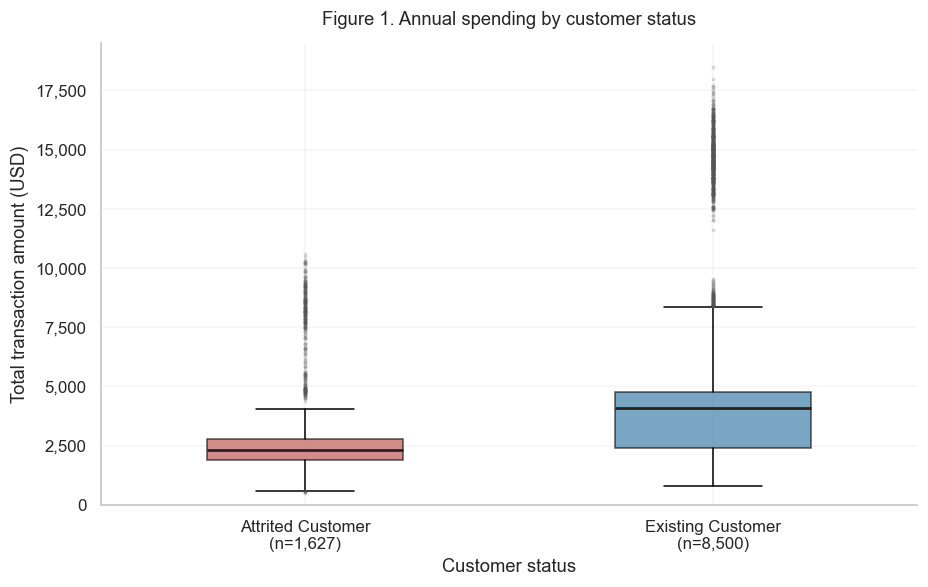

In [4]:
fig, ax = plt.subplots(figsize=(8.6, 5.5))
groups = [df.loc[df['Attrition_Flag'].eq(label), 'Total_Trans_Amt'] for label in STATUS_ORDER]
boxes = ax.boxplot(
    groups, tick_labels=[f'{label}\n(n={len(values):,})' for label, values in zip(STATUS_ORDER, groups)],
    patch_artist=True, widths=0.48, showfliers=True,
    medianprops={'color': '#222222', 'linewidth': 1.8},
    flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.23, 'markeredgecolor': '#555555'}
)
for patch, label in zip(boxes['boxes'], STATUS_ORDER):
    patch.set_facecolor(STATUS_COLORS[label])
    patch.set_alpha(0.65)
ax.set(title='Figure 1. Annual spending by customer status',
       xlabel='Customer status', ylabel='Total transaction amount (USD)', ylim=(0, 19500))
ax.yaxis.set_major_formatter(usd_ticks)
fig.tight_layout()
plt.show()

**Interpretation of Figure 1 and the summary table.** Attrited customers have a median of **\$2,329**, compared with **\$4,100** for existing customers: a **\$1,771 gap**, or **43.20% lower** relative to the existing-customer median. The means are **\$3,095.03** and **\$4,654.66**, respectively. Thus, the group difference is visible in both robust and classical summaries, and is not just an average driven by a few large amounts.

Attrited customers have a narrower central distribution: IQR **\$868.50** (Q1 \$1,903.50; Q3 \$2,772), versus **\$2,396.50** (Q1 \$2,384.75; Q3 \$4,781.25). The sample SDs are \$2,308.23 and \$3,512.77. Both groups have right tails; individual spending overlaps substantially, so status does not identify an individual's spending level perfectly. Figure 1 includes all plotted fliers, and the group summaries include every observation.

In [5]:
def tail_summary(frame, group_column, order):
    rows = []
    for label in order:
        values = frame.loc[frame[group_column].eq(label), 'Total_Trans_Amt']
        q1, q3 = values.quantile([0.25, 0.75])
        upper_fence = q3 + 1.5 * (q3 - q1)
        rows.append({
            group_column: label, 'n': len(values), 'Upper group fence': upper_fence,
            'Above fence': int(values.gt(upper_fence).sum()),
            'Above fence (%)': 100 * values.gt(upper_fence).mean(), 'Maximum': values.max()
        })
    return pd.DataFrame(rows).set_index(group_column)


display(tail_summary(df, 'Attrition_Flag', STATUS_ORDER).round(2))
attrited_amounts = df.loc[df['Attrition_Flag'].eq('Attrited Customer'), 'Total_Trans_Amt']
q1_attrited, q3_attrited = attrited_amounts.quantile([0.25, 0.75])
lower_attrited_fence = q1_attrited - 1.5 * (q3_attrited - q1_attrited)
print(f'Attrited lower fence: ${lower_attrited_fence:,.2f}; observations below it: {attrited_amounts.lt(lower_attrited_fence).sum()}')
focus_ids = [810347208, 718140783, 708163758]
display(df.loc[df['CLIENTNUM'].isin(focus_ids), [
    'CLIENTNUM', 'Attrition_Flag', 'Card_Category', 'Credit_Limit',
    'Total_Trans_Amt', 'Total_Trans_Ct'
]].set_index('CLIENTNUM'))

,n,Upper group fence,Above fence,Above fence (%),Maximum
Attrition_Flag,,,,,
Attrited Customer,1627,4074.75,308,18.93,10583
Existing Customer,8500,8376.00,849,9.99,18484


Attrited lower fence: $600.75; observations below it: 7


,Attrition_Flag,Card_Category,Credit_Limit,Total_Trans_Amt,Total_Trans_Ct
CLIENTNUM,,,,,
810347208,Existing Customer,Gold,34516.0,1330,31
708163758,Existing Customer,Blue,34516.0,13085,139
718140783,Existing Customer,Blue,10585.0,18484,108


**Unusual observations.** The group-specific upper fences are **\$4,074.75** for attrited and **\$8,376.00** for existing customers. They flag **308 (18.93%)** and **849 (9.99%)** observations, respectively; maxima are **\$10,583** and **\$18,484**. Different fences describe different within-group distributions, so the larger flagged percentage does not mean that attrited customers spend more. An IQR flag is a screening label, not proof of an error.

At the lower end, seven attrited customers fall below their group's \$600.75 lower fence; the group's minimum is \$510. These low-spending records are also retained. Existing customers have no observations below their lower fence, which is negative.

The three Assignment 2 cases remain in the data. Customer **718140783** spends \$18,484 across 108 transactions; **708163758** has 139 transactions and spends \$13,085. Customer **810347208** has the maximum \$34,516 limit but only \$1,330 in transactions. Their records remain internally plausible. The high-spending tails lift the means in both groups, which is why medians and IQRs are central to the comparison.

## 2. Compare more than two groups: spending by card category

We retain **the same numerical variable, `Total_Trans_Amt`**, and compare Blue, Silver, Gold, and Platinum cards. This extends Assignment 3's credit-limit-by-card analysis to actual spending. A common vertical scale allows direct comparison; sample sizes are part of the tick labels. All 20 Platinum observations are additionally shown with horizontal jitter so the small group's limited support is visible.

In [6]:
card_summary = group_summary(df, 'Card_Category', CARD_ORDER)
display(card_summary.round(2))
display(tail_summary(df, 'Card_Category', CARD_ORDER).round(2))

pooled_q1, pooled_q3 = df['Total_Trans_Amt'].quantile([0.25, 0.75])
pooled_amount_fence = pooled_q3 + 1.5 * (pooled_q3 - pooled_q1)
pooled_tail_by_card = (df.assign(Above_pooled_fence=df['Total_Trans_Amt'].gt(pooled_amount_fence))
                      .groupby('Card_Category')['Above_pooled_fence']
                      .agg(Count='sum', Fraction='mean').reindex(CARD_ORDER))
pooled_tail_by_card['Percent'] = 100 * pooled_tail_by_card.pop('Fraction')
print(f'Comparison using the common Assignment 2 amount fence: ${pooled_amount_fence:,.2f}')
display(pooled_tail_by_card.round(2))

print(f'Blue share of customers: {100 * card_summary.loc["Blue", "n"] / len(df):.2f}%')
print(f'Largest median contrast (Platinum minus Blue): ${card_summary.loc["Platinum", "Median"] - card_summary.loc["Blue", "Median"]:,.2f}')

,n,Mean,Median,Q1,Q3,IQR,SD
Card_Category,,,,,,,
Blue,9436,4225.41,3856.5,2132.0,4679.25,2547.25,3196.10
Silver,555,6590.48,4303.0,2918.0,8830.00,5912.00,4841.86
Gold,116,7685.61,7652.5,4040.5,9320.00,5279.50,4571.75
Platinum,20,8999.75,8427.0,5253.0,13881.25,8628.25,4934.73


,n,Upper group fence,Above fence,Above fence (%),Maximum
Card_Category,,,,,
Blue,9436,8500.12,728,7.72,18484
Silver,555,17698.00,0,0.00,17628
Gold,116,17239.25,0,0.00,16328
Platinum,20,26823.62,0,0.00,16712


Comparison using the common Assignment 2 amount fence: $8,619.25


,Count,Percent
Card_Category,,
Blue,703,7.45
Silver,150,27.03
Gold,34,29.31
Platinum,9,45.00


Blue share of customers: 93.18%
Largest median contrast (Platinum minus Blue): $4,570.50


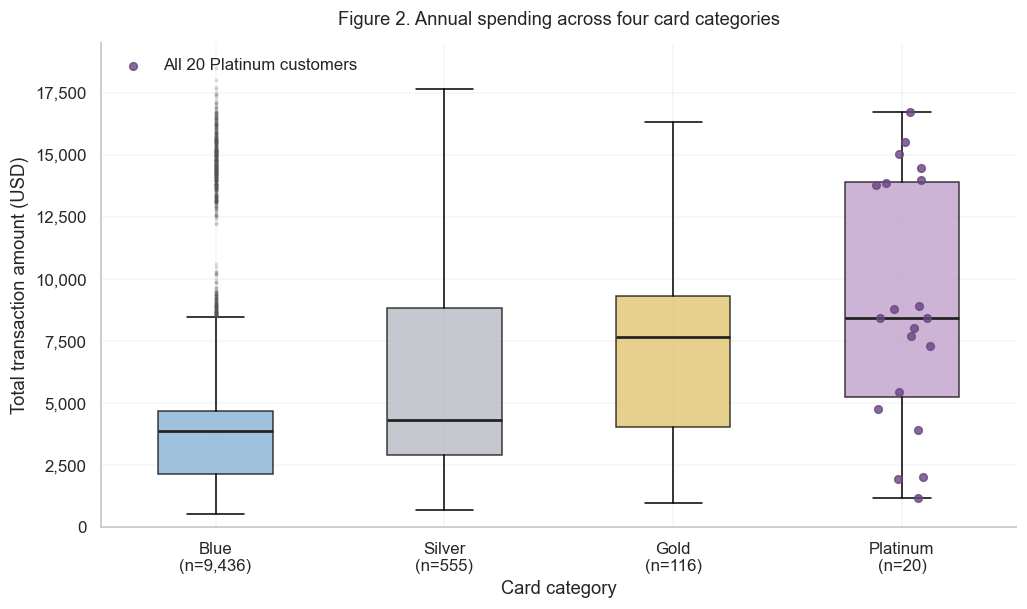

In [7]:
fig, ax = plt.subplots(figsize=(9.5, 5.7))
card_groups = [df.loc[df['Card_Category'].eq(label), 'Total_Trans_Amt'] for label in CARD_ORDER]
boxes = ax.boxplot(
    card_groups, tick_labels=[f'{label}\n(n={len(values):,})' for label, values in zip(CARD_ORDER, card_groups)],
    patch_artist=True, widths=0.50, showfliers=True,
    medianprops={'color': '#222222', 'linewidth': 1.8},
    flierprops={'marker': '.', 'markersize': 2.8, 'alpha': 0.20, 'markeredgecolor': '#555555'}
)
for patch, color in zip(boxes['boxes'], CARD_COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
rng = np.random.default_rng(RANDOM_SEED)
ax.scatter(4 + rng.uniform(-0.13, 0.13, len(card_groups[-1])), card_groups[-1],
           s=25, color='#694581', alpha=0.80, zorder=3, label='All 20 Platinum customers')
ax.set(title='Figure 2. Annual spending across four card categories',
       xlabel='Card category', ylabel='Total transaction amount (USD)', ylim=(0, 19500))
ax.yaxis.set_major_formatter(usd_ticks)
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
plt.show()

**Interpretation of Figure 2.** Median spending rises from **\$3,856.50** for Blue to **\$4,303** for Silver, **\$7,652.50** for Gold, and **\$8,427** for Platinum. The largest observed median difference is **Platinum versus Blue: \$4,570.50**, about 2.19 times the Blue median. The Blue–Silver median gap is only **\$446.50**, although their mean gap is much larger (\$6,590.48 versus \$4,225.41). Silver's long upper range explains why a comparison based only on means would exaggerate its typical-customer difference from Blue.

The middle spread is also different: IQRs are **\$2,547.25 (Blue)**, **\$5,912.00 (Silver)**, **\$5,279.50 (Gold)**, and **\$8,628.25 (Platinum)**. These distributions overlap. Blue has 9,436 customers (**93.18%** of the file), Silver 555, Gold 116, and Platinum only 20. The apparent premium-card pattern is therefore most uncertain for Platinum; each observation represents 5% of that group. A high median in 20 customers does not establish a stable population difference or an effect of upgrading a card.

Blue has 728 observations above its own upper IQR fence. The other categories have no upper IQR fliers because their central distributions and fences are much wider, even though their amounts can be high in absolute USD. The pooled \$8,619.25 fence from Assignment 2 would flag 703 Blue, 150 Silver, 34 Gold, and 9 Platinum customers. Thus, an outlier label depends on the reference distribution. All customers remain in the main analysis.

## 3. Stratification and possible confounding

### 3.1 Revisit Assignment 3: credit limit versus spending

Assignment 3 found a weak positive Pearson correlation but almost no rank correlation between `Credit_Limit` and `Total_Trans_Amt`. We now stratify this **same pair** by all six recorded income categories, retaining `Unknown` separately. Income is a plausible confounder because purchasing resources and credit allocation could both depend on it; these mechanisms are hypotheses, not established causal facts in this file.

We compare each subgroup's direction and strength using Pearson r, Spearman ρ, and descriptive straight lines. The panels share axis limits. The dashed pooled line is repeated as a reference; each solid line is fitted within the displayed group. Lines are descriptive OLS summaries, not causal effects or evidence of a globally linear relationship.

In [8]:
def relationship_summary(frame):
    return {
        'n': len(frame),
        'Pearson r': frame['Credit_Limit'].corr(frame['Total_Trans_Amt']),
        'Spearman rho': frame['Credit_Limit'].corr(frame['Total_Trans_Amt'], method='spearman'),
        'Median limit': frame['Credit_Limit'].median(),
        'Median amount': frame['Total_Trans_Amt'].median(),
        'At max limit (%)': 100 * frame['Credit_Limit'].eq(credit_max).mean()
    }


income_relationships = pd.DataFrame.from_dict(
    {'All customers': relationship_summary(df), **{
        label: relationship_summary(df.loc[df['Income_Category'].eq(label)])
        for label in INCOME_ORDER
    }}, orient='index'
)
income_relationships['n'] = income_relationships['n'].astype(int)
display(income_relationships.round(4))

pair_columns = ['Credit_Limit', 'Total_Trans_Amt']
within_income = df[pair_columns] - df.groupby('Income_Category')[pair_columns].transform('mean')
within_income_r = within_income['Credit_Limit'].corr(within_income['Total_Trans_Amt'])
print(f'Pooled Pearson r: {income_relationships.loc["All customers", "Pearson r"]:.4f}')
print(f'Pearson r after removing income-category means: {within_income_r:.4f}')

,n,Pearson r,Spearman rho,Median limit,Median amount,At max limit (%)
All customers,10127,0.1717,0.0284,4549.0,3899.0,5.0163
Less than $40K,3561,0.2745,0.0761,2766.0,4099.0,0.0000
$40K - $60K,1790,0.2260,0.0571,3682.0,3967.0,0.0000
$60K - $80K,1402,0.2483,0.1454,7660.0,3552.5,3.4950
$80K - $120K,1535,0.1933,0.1245,12830.0,3525.0,14.0065
$120K +,727,0.1688,0.1202,18442.0,3643.0,27.9230
Unknown,1112,0.2320,0.0066,6380.0,4107.0,3.6871


Pooled Pearson r: 0.1717
Pearson r after removing income-category means: 0.2001


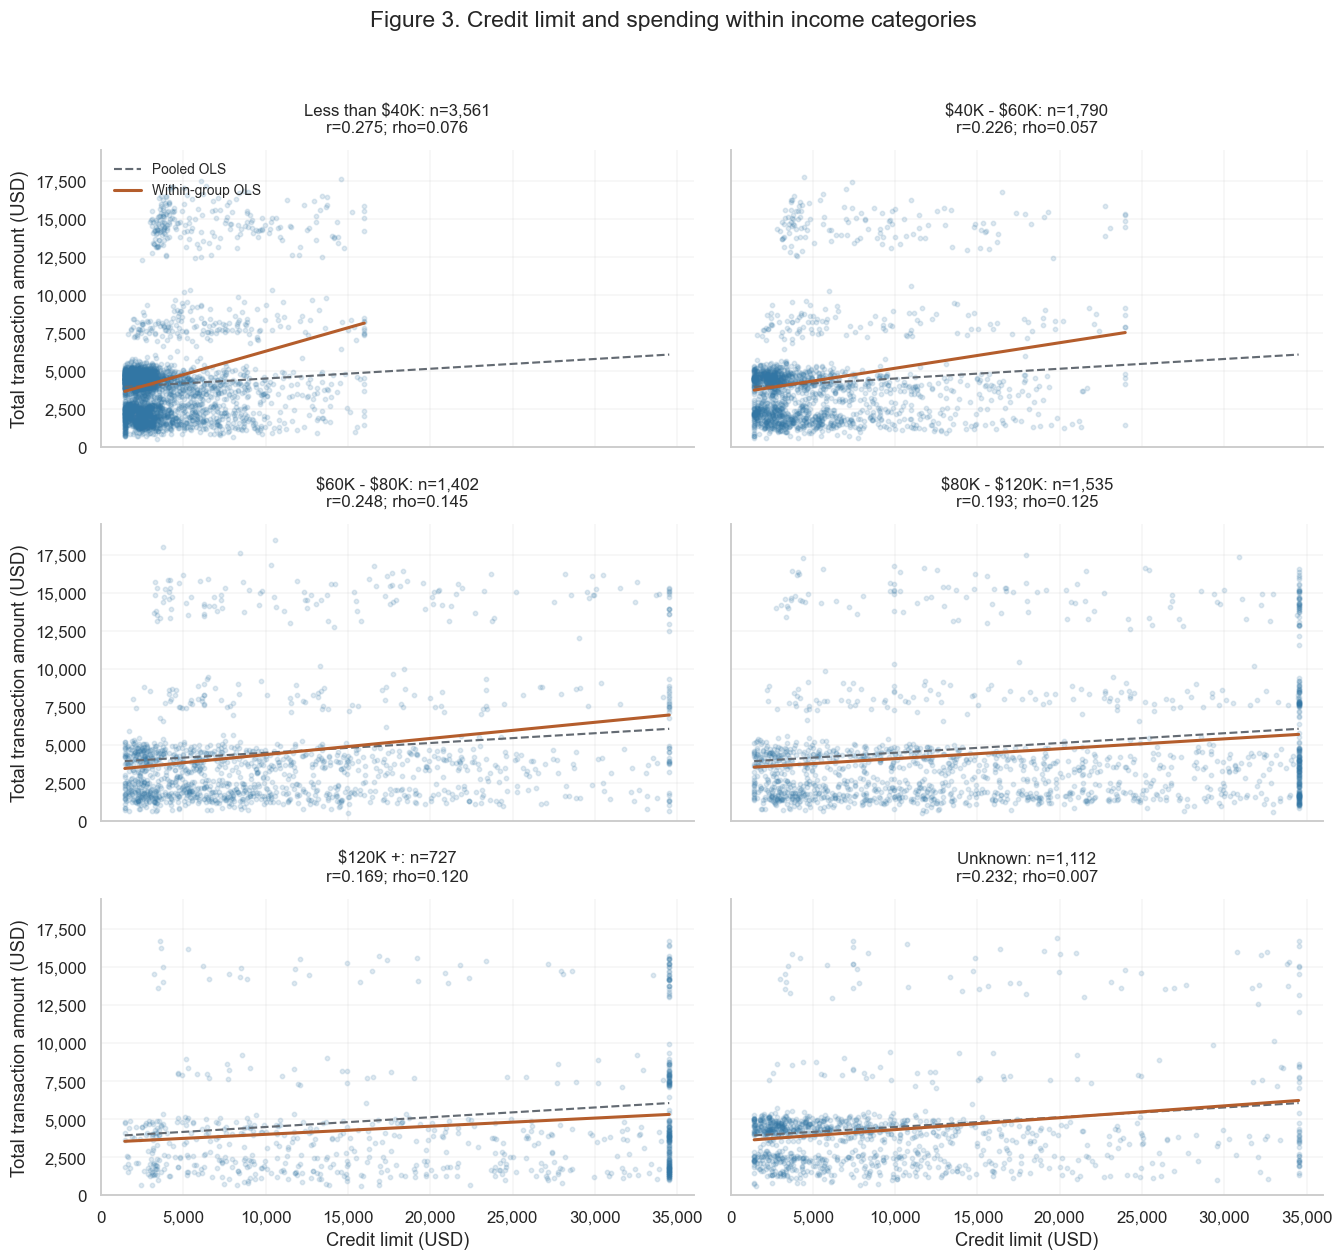

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(12.4, 11.5), sharex=True, sharey=True)
pooled_fit = np.polyfit(df['Credit_Limit'], df['Total_Trans_Amt'], 1)
xx_pooled = np.array([df['Credit_Limit'].min(), credit_max])
for ax, label in zip(axes.flat, INCOME_ORDER):
    group = df.loc[df['Income_Category'].eq(label)]
    ax.scatter(group['Credit_Limit'], group['Total_Trans_Amt'], s=8, alpha=0.15,
               color='#3276a4', rasterized=True)
    xx_group = np.array([group['Credit_Limit'].min(), group['Credit_Limit'].max()])
    group_fit = np.polyfit(group['Credit_Limit'], group['Total_Trans_Amt'], 1)
    ax.plot(xx_pooled, np.polyval(pooled_fit, xx_pooled), '--', color='#646b73', lw=1.4, label='Pooled OLS')
    ax.plot(xx_group, np.polyval(group_fit, xx_group), color='#b45d2c', lw=2, label='Within-group OLS')
    row = income_relationships.loc[label]
    ax.set_title(f'{label}: n={len(group):,}\nr={row["Pearson r"]:.3f}; rho={row["Spearman rho"]:.3f}', fontsize=11)
    ax.set(xlim=(0, 36000), ylim=(0, 19500))
    ax.xaxis.set_major_formatter(usd_ticks)
    ax.yaxis.set_major_formatter(usd_ticks)
for ax in axes[-1]:
    ax.set_xlabel('Credit limit (USD)')
for ax in axes[:, 0]:
    ax.set_ylabel('Total transaction amount (USD)')
axes[0, 0].legend(frameon=False, fontsize=9, loc='upper left')
fig.suptitle('Figure 3. Credit limit and spending within income categories', fontsize=15, y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

### 3.2 What stratification changes

**Direction:** every income category has a positive Pearson coefficient, approximately **0.169–0.275**, compared with **0.172 overall**. There is **no sign reversal or Simpson's-paradox claim**. The weakest subgroup linear association is in `$120K +` (r ≈ 0.169), and the strongest is in `Less than $40K` (r ≈ 0.275). Even the largest coefficient is modest and accompanies substantial vertical scatter.

**Strength and shape:** subgroup Spearman coefficients range only from about **0.007 to 0.145**, versus **0.028 overall**. The positive fitted slopes therefore do not establish a reliable monotonic spending ranking by limit. Tails and the repeated maximum remain relevant. Removing income-category means from both variables yields a residual correlation of **0.200**, only a modest increase from 0.172. This calculation removes between-income mean differences, but is not full causal adjustment and does not model nonlinearities or interactions.

**Why income matters:** median credit limits vary from **\$2,766** in `Less than $40K` to **\$18,442** in `$120K +`, while median spending is **\$4,099** and **\$3,643**, respectively. Group composition therefore changes what the pooled cloud represents. Moreover, **27.92%** of the `$120K +` group is at the recorded maximum limit, compared with zero in the two lowest known-income categories. The available x-range differs between strata even though the displayed scales are common. `Unknown` is not an income level and its panel should not be placed on an ordinal income trend.

**Conclusion:** stratification adds context and shows modest heterogeneity, but the earlier conclusion survives: credit limit alone has a weak and unstable relationship with spending. Income is a possible common influence, not a demonstrated explanation. Card category, transaction frequency, and unobserved financial circumstances could also affect the pattern.

## 4. Chi-square test of independence and Cramér's V

### 4.1 Question, hypotheses and assumptions

We test the income–attrition question introduced in Assignment 1 using **`Income_Category` and `Attrition_Flag`**. These two variables are selected for that substantive question, rather than by screening many categorical pairs for small p-values.

- **H₀:** recorded income category and attrition status are independent.
- **H₁:** recorded income category and attrition status are associated.
- **Significance level:** α = **0.05**.

The test uses counts, mutually exclusive categories, and one row per distinct customer. We treat customers as independent observational units. Unique identifiers rule out duplicate customers but do not establish random sampling or independence of related households. The inferential interpretation is conditional on those assumptions; this dataset is not demonstrated to be representative of every bank's customers.

`Unknown` remains a sixth recorded income category in the primary analysis. Small card groups are not used for this test: for example, the expected attrited count in Platinum would be about 3.21, whereas the chosen income table has large expected cell counts.

In [10]:
observed = pd.crosstab(df['Income_Category'], df['Attrition_Flag']).reindex(
    index=INCOME_ORDER, columns=STATUS_ORDER
)
observed_with_totals = observed.copy()
observed_with_totals['Total'] = observed.sum(axis=1)
observed_with_totals.loc['Total'] = observed_with_totals.sum(axis=0)
display(observed_with_totals)

# Margins are for presentation only; the test uses the original 6 × 2 counts.
chi2_stat, p_value, degrees_freedom, expected_array = chi2_contingency(observed, correction=False)
expected = pd.DataFrame(expected_array, index=observed.index, columns=observed.columns)
print('Expected counts under independence:')
display(expected.round(2))
print(f'Minimum expected count: {expected_array.min():.2f}')
print(f'Expected counts below 5: {(expected_array < 5).sum()} / {expected_array.size}')

Attrition_Flag,Attrited Customer,Existing Customer,Total
Income_Category,,,
Less than $40K,612,2949,3561
$40K - $60K,271,1519,1790
$60K - $80K,189,1213,1402
$80K - $120K,242,1293,1535
$120K +,126,601,727
Unknown,187,925,1112
Total,1627,8500,10127


Expected counts under independence:


Attrition_Flag,Attrited Customer,Existing Customer
Income_Category,,
Less than $40K,572.11,2988.89
$40K - $60K,287.58,1502.42
$60K - $80K,225.24,1176.76
$80K - $120K,246.61,1288.39
$120K +,116.80,610.20
Unknown,178.65,933.35


Minimum expected count: 116.80
Expected counts below 5: 0 / 12


### 4.2 Calculation

For observed count $O_{ij}$, row total $R_i$, column total $C_j$, and total $N$:

$$E_{ij}=\frac{R_i C_j}{N},\qquad
\chi^2=\sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}},\qquad
df=(r-1)(c-1).$$

$$V=\sqrt{\frac{\chi^2}{N\min(r-1,c-1)}}.$$

Here $r=6$, $c=2$, $N=10{,}127$, and $df=5$. We use the ordinary Pearson statistic without Yates' correction; that correction is not relevant to this 6 × 2 table. Cramér's V is the uncorrected version requested in the assignment. It measures strength on a 0–1 scale and has no direction.

In [11]:
n_test = int(observed.to_numpy().sum())
n_rows, n_columns = observed.shape
expected_manual = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / n_test
chi2_manual = np.sum((observed.to_numpy() - expected_manual) ** 2 / expected_manual)
cramers_v = np.sqrt(chi2_stat / (n_test * min(n_rows - 1, n_columns - 1)))

# Check the formulas against SciPy using the same table and no margins.
assert np.allclose(expected_manual, expected_array)
assert np.isclose(chi2_manual, chi2_stat)
assert degrees_freedom == (n_rows - 1) * (n_columns - 1)
assert n_test == len(df)
assert expected_array.min() >= 5

test_results = pd.DataFrame([{
    'N': n_test, 'Chi-square': chi2_stat, 'df': degrees_freedom,
    'p-value': p_value, "Cramer's V": cramers_v,
    'Decision at alpha=0.05': 'Reject H0' if p_value < ALPHA else 'Do not reject H0'
}])
display(test_results.round(6))

income_percentages = observed.div(observed.sum(axis=1), axis=0) * 100
print('Within-income percentages:')
display(income_percentages.round(2))

,N,Chi-square,df,p-value,Cramer's V,Decision at alpha=0.05
0,10127,12.832259,5,0.025002,0.035597,Reject H0


Within-income percentages:


Attrition_Flag,Attrited Customer,Existing Customer
Income_Category,,
Less than $40K,17.19,82.81
$40K - $60K,15.14,84.86
$60K - $80K,13.48,86.52
$80K - $120K,15.77,84.23
$120K +,17.33,82.67
Unknown,16.82,83.18


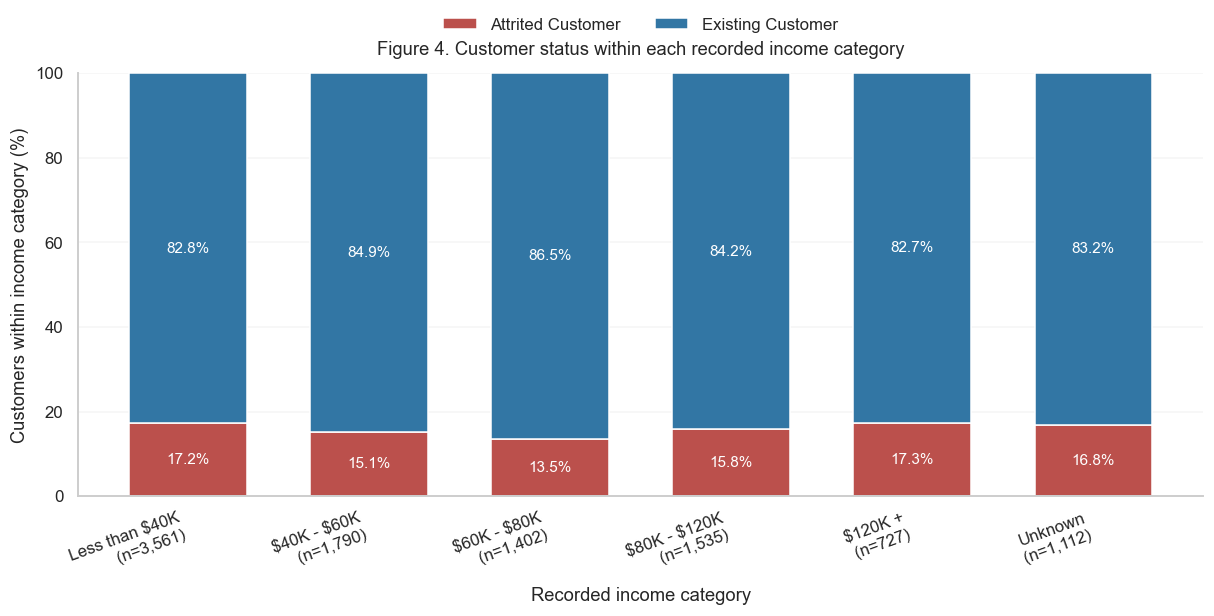

In [12]:
fig, ax = plt.subplots(figsize=(11.2, 5.8))
x = np.arange(len(INCOME_ORDER))
attrited_pct = income_percentages['Attrited Customer'].to_numpy()
existing_pct = income_percentages['Existing Customer'].to_numpy()
ax.bar(x, attrited_pct, width=0.65, color=STATUS_COLORS['Attrited Customer'], label='Attrited Customer')
ax.bar(x, existing_pct, bottom=attrited_pct, width=0.65,
       color=STATUS_COLORS['Existing Customer'], label='Existing Customer')
for position, a, e in zip(x, attrited_pct, existing_pct):
    ax.text(position, a / 2, f'{a:.1f}%', ha='center', va='center', color='white', fontsize=10)
    ax.text(position, a + e / 2, f'{e:.1f}%', ha='center', va='center', color='white', fontsize=10)
ax.set_xticks(x, [f'{label}\n(n={int(observed.loc[label].sum()):,})' for label in INCOME_ORDER],
              rotation=20, ha='right')
ax.set(title="Figure 4. Customer status within each recorded income category",
       xlabel='Recorded income category', ylabel='Customers within income category (%)', ylim=(0, 100))
ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.06), ncol=2)
ax.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

### 4.3 Statistical significance versus association strength

The test gives **χ² = 12.8323**, **df = 5**, **p = 0.025002**, and **Cramér's V = 0.03560**. The minimum expected frequency is **116.80** and no expected count is below 5, so sparsity does not undermine the chi-square approximation here.

Because p < 0.05, we **reject independence at the specified level**, subject to the sampling and independence assumptions above. This does not mean that the probability of H₀ is 2.5%, that income causes attrition, or that the differences are large. V is close to zero, indicating a **very weak association** on its 0–1 scale. Effect-size labels are contextual rather than universal thresholds; the actual magnitude and rate differences are more useful here.

Figure 4 shows attrition rates from **13.48%** for `$60K - $80K` to **17.33%** for `$120K +`, a spread of about **3.85 percentage points**. The lowest-income group is also relatively high at **17.19%**, so there is no simple monotonic income gradient. This supports Assignment 1's descriptive conclusion that income alone is not a strong discriminator, while adding evidence of a small departure from exact independence. The omnibus test does not establish which individual category pairs differ; we make no uncorrected pairwise significance claims.

In [13]:
# Sensitivity to treating Unknown as a recorded category.
# This is a different, restricted population, not a replacement primary test.
known_income = df.loc[df['Income_Category'].ne('Unknown')]
known_table = pd.crosstab(known_income['Income_Category'], known_income['Attrition_Flag'])
known_chi2, known_p, known_df, known_expected = chi2_contingency(known_table, correction=False)
known_v = np.sqrt(known_chi2 / (len(known_income) * min(known_table.shape[0] - 1, known_table.shape[1] - 1)))
display(pd.DataFrame([
    {'Population': 'All recorded income categories', 'N': n_test,
     'Chi-square': chi2_stat, 'df': degrees_freedom, 'p-value': p_value, "Cramer's V": cramers_v},
    {'Population': 'Known income only (sensitivity)', 'N': len(known_income),
     'Chi-square': known_chi2, 'df': known_df, 'p-value': known_p, "Cramer's V": known_v}
]).set_index('Population').round(6))

,N,Chi-square,df,p-value,Cramer's V
Population,,,,,
All recorded income categories,10127,12.832259,5,0.025002,0.035597
Known income only (sensitivity),9015,12.368085,4,0.014814,0.037040


**Sensitivity interpretation.** Excluding the 1,112 `Unknown` income records leaves **N = 9,015**, χ² ≈ **12.3681**, df = **4**, p ≈ **0.01481**, and V ≈ **0.03704**. The magnitude remains very small. This is a check on category handling, not a second independent discovery: excluding unknown-income customers changes the analyzed population and may introduce selection differences. Both calculations support the same practical interpretation.

## 5. Explore several numerical variables together

We select **six original numerical variables**. No customer ID, category codes, attrition labels, or previous classifier probabilities enter the numerical matrices. Attrition is used only to color the pair plot and, later, the PCA scores.

| Variable | Meaning and units |
|---|---|
| `Total_Trans_Ct` | Total transaction count |
| `Total_Trans_Amt` | Total transaction amount, USD |
| `Credit_Limit` | Recorded credit limit, USD |
| `Avg_Utilization_Ratio` | Credit utilization, a ratio between 0 and 1 |
| `Customer_Age` | Age, years |
| `Months_on_book` | Account tenure, months |

The lower-triangle pair plot is equivalent to a full scatterplot matrix without duplicate mirrored panels. Every observation is plotted. Diagonal histograms show **within-status densities**, normalized separately, so unequal group sizes do not alone determine histogram height. Transparent points reduce overplotting; they do not eliminate it.

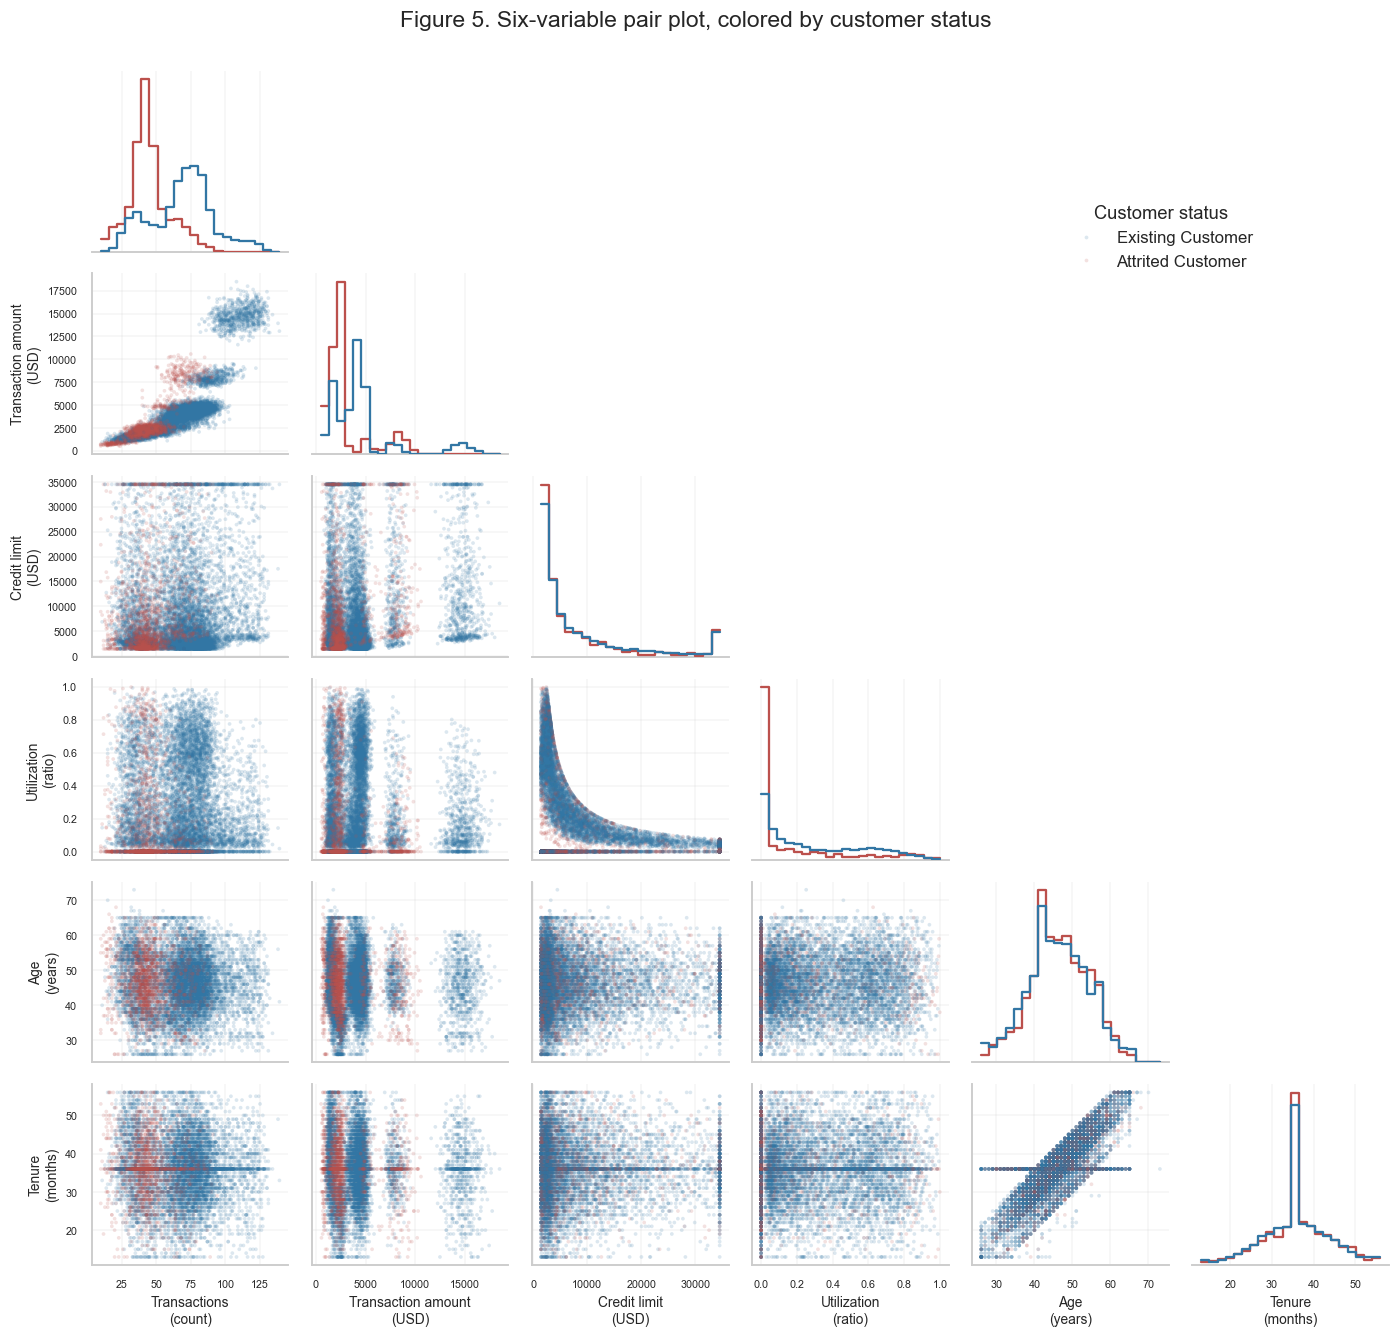

In [14]:
numeric_columns = [
    'Total_Trans_Ct', 'Total_Trans_Amt', 'Credit_Limit',
    'Avg_Utilization_Ratio', 'Customer_Age', 'Months_on_book'
]
short_labels = {
    'Total_Trans_Ct': 'Transactions\n(count)',
    'Total_Trans_Amt': 'Transaction amount\n(USD)',
    'Credit_Limit': 'Credit limit\n(USD)',
    'Avg_Utilization_Ratio': 'Utilization\n(ratio)',
    'Customer_Age': 'Age\n(years)',
    'Months_on_book': 'Tenure\n(months)'
}
pair_data = df[numeric_columns + ['Attrition_Flag']].rename(
    columns={**short_labels, 'Attrition_Flag': 'Customer status'}
)
pair_grid = sns.pairplot(
    pair_data, vars=list(short_labels.values()), hue='Customer status',
    hue_order=DRAW_ORDER, palette=STATUS_COLORS,
    corner=True, diag_kind='hist', height=1.95, grid_kws={'diag_sharey': False},
    plot_kws={'s': 6, 'alpha': 0.17, 'linewidth': 0, 'rasterized': True},
    diag_kws={'bins': 22, 'stat': 'density', 'common_norm': False, 'element': 'step', 'fill': False}
)
pair_grid.figure.set_size_inches(13.4, 12.2)
pair_grid.figure.suptitle('Figure 5. Six-variable pair plot, colored by customer status', y=1.005, fontsize=15)
for ax in pair_grid.axes.flat:
    if ax is not None:
        ax.tick_params(labelsize=7)
        ax.xaxis.label.set_size(9)
        ax.yaxis.label.set_size(9)
if pair_grid.legend is not None:
    pair_grid.legend.set_bbox_to_anchor((0.86, 0.82))
pair_grid.figure.subplots_adjust(left=0.09, bottom=0.07, right=0.97, top=0.96, hspace=0.12, wspace=0.12)
plt.show()

**Figure 5: visual reading.** The transaction-count–amount panel has a clear increasing band and several activity concentrations, with attrited customers concentrated more strongly in the lower-activity part. The age–tenure panel also increases strongly. In contrast, age–credit limit is a diffuse cloud with no clear tilt. Credit limit–utilization has a curved pattern, many utilization zeros, and a stack at the maximum limit: a straight-line description is incomplete. Color overlap remains substantial, so these plots do not demonstrate a clean separation of attrition classes.

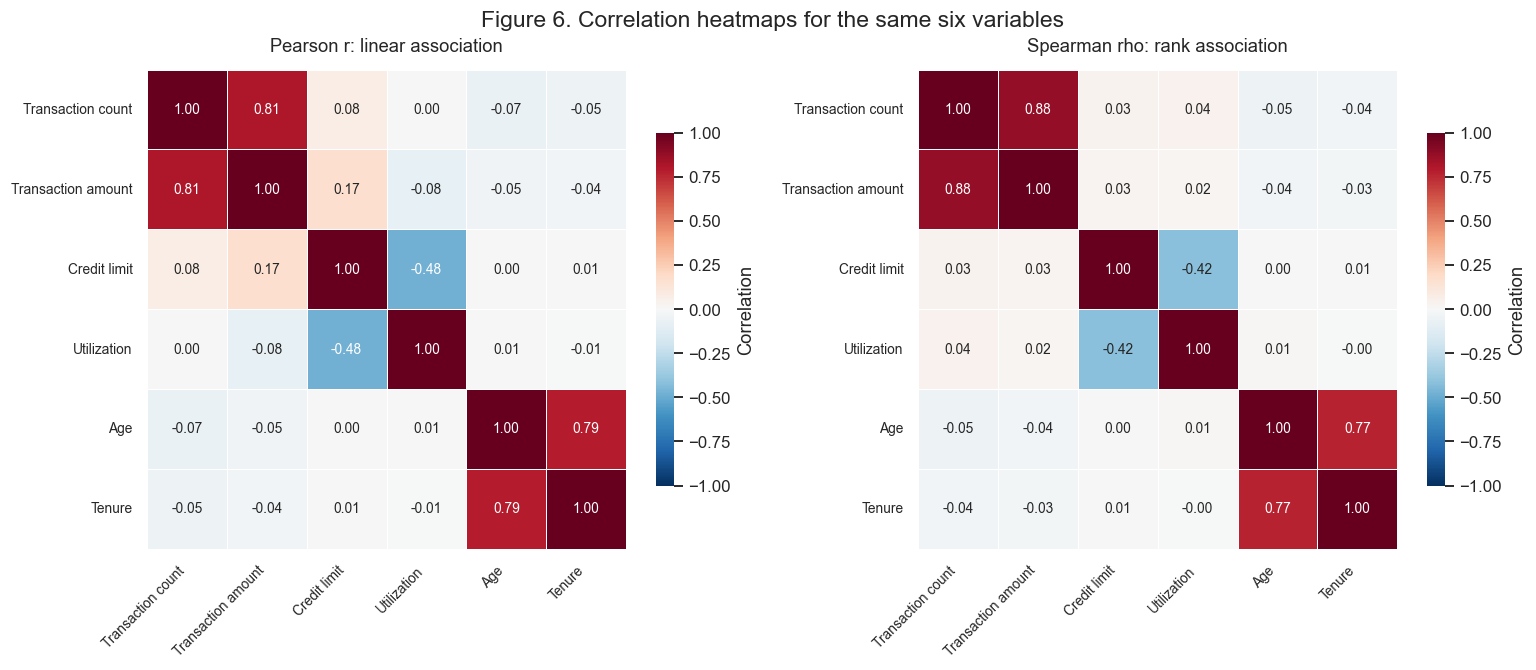

,Pearson r,Spearman rho
Pair,,
Total_Trans_Ct / Total_Trans_Amt,0.8072,0.8797
Customer_Age / Months_on_book,0.7889,0.7689
Credit_Limit / Avg_Utilization_Ratio,-0.4830,-0.4170
Customer_Age / Credit_Limit,0.0025,0.0024


In [15]:
pearson_matrix = df[numeric_columns].corr(method='pearson')
spearman_matrix = df[numeric_columns].corr(method='spearman')
heat_labels = ['Transaction count', 'Transaction amount', 'Credit limit', 'Utilization', 'Age', 'Tenure']

fig, axes = plt.subplots(1, 2, figsize=(14.2, 6.0))
for ax, matrix, title in zip(axes, [pearson_matrix, spearman_matrix], ['Pearson r: linear association', 'Spearman rho: rank association']):
    sns.heatmap(matrix, ax=ax, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
                annot=True, fmt='.2f', square=True, linewidths=0.5,
                xticklabels=heat_labels, yticklabels=heat_labels,
                cbar_kws={'shrink': 0.70, 'label': 'Correlation'}, annot_kws={'size': 9})
    ax.set_title(title)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)
fig.suptitle('Figure 6. Correlation heatmaps for the same six variables', fontsize=15)
fig.tight_layout()
plt.show()

interesting_pairs = [
    ('Total_Trans_Ct', 'Total_Trans_Amt'),
    ('Customer_Age', 'Months_on_book'),
    ('Credit_Limit', 'Avg_Utilization_Ratio'),
    ('Customer_Age', 'Credit_Limit')
]
display(pd.DataFrame([
    {'Pair': f'{left} / {right}', 'Pearson r': pearson_matrix.loc[left, right],
     'Spearman rho': spearman_matrix.loc[left, right]}
    for left, right in interesting_pairs
]).set_index('Pair').round(4))

### 5.1 Visual patterns versus coefficients

1. **Interesting relationship 1 — transaction count and amount:** Pearson **r = 0.8072**, Spearman **ρ = 0.8797**. Both agree with the increasing band in Figure 5. The rank relationship is stronger than the linear relationship because spending is not a uniform dollar increase per additional transaction. Total spending also accumulates over transactions by definition, so this is partly an arithmetic relationship rather than an independent behavioral effect.
2. **Interesting relationship 2 — age and tenure:** Pearson **r = 0.7889**, Spearman **ρ = 0.7689**. The diagonal cloud supports a strong positive relationship. Older customers have had more opportunity to hold accounts longer; life-cycle and cohort composition could both contribute. Age and tenure should not be interpreted as two independent pieces of the same evidence.
3. **Additional nonlinear relationship — limit and utilization:** Pearson **r = −0.4830**, Spearman **ρ = −0.4170**. The average direction is negative, but the curved cloud, zeros, and recorded maximum show why neither number fully describes its shape. Utilization is closely related to revolving balance divided by limit, so the denominator itself contributes to the association.
4. **Weak relationship — age and credit limit:** Pearson **r = 0.0025**, Spearman **ρ = 0.0024**. Both are essentially zero and agree with the lack of a visible overall tilt. This is weak marginal evidence, not proof that no conditional or nonlinear relationship can exist.

The multivariate view adds two things to isolated bivariate plots: it exposes redundant information in the activity and life-cycle pairs, and shows that financial capacity/utilization provide another dimension. The correlations remain pairwise marginal quantities; a heatmap does not adjust one variable for all the others.

## 6. Principal component analysis

### 6.1 Why PCA is appropriate and how it is fitted

The six selected variables are numerical and complete, and they contain correlated pairs, making PCA a reasonable exploratory summary. Their units and ranges differ greatly, so we **standardize all six variables to mean zero and population SD one** using `StandardScaler`, then fit full-SVD PCA. Standardization prevents raw USD magnitudes alone from dominating, but does not remove skewness or outlier influence.

The primary PCA uses the same original variables as the pair plot and heatmaps. Every customer is used, and no extremes are deleted. Attrition and income are excluded from fitting; status colors are added only after projecting the data. Since this is descriptive EDA rather than a prediction assessment, fitting to the complete dataset does not provide or claim held-out performance.

We report explained variance for all six components, show PC1 versus PC2, and inspect the component coefficients. A separate sensitivity check logs the positive monetary variables, consistent with the transformation lesson from Assignment 2.

In [16]:
scaler = StandardScaler()
standardized = scaler.fit_transform(df[numeric_columns])
assert np.allclose(standardized.mean(axis=0), 0, atol=1e-12)
assert np.allclose(standardized.std(axis=0, ddof=0), 1)

pca = PCA(svd_solver='full')
scores = pca.fit_transform(standardized)
component_names = [f'PC{i + 1}' for i in range(len(numeric_columns))]
variance_table = pd.DataFrame({
    'Explained variance (%)': 100 * pca.explained_variance_ratio_,
    'Cumulative (%)': 100 * np.cumsum(pca.explained_variance_ratio_)
}, index=component_names)
component_coefficients = pd.DataFrame(
    pca.components_.T, index=numeric_columns, columns=component_names
)
assert np.isclose(pca.explained_variance_ratio_.sum(), 1)
assert np.allclose(pca.components_ @ pca.components_.T, np.eye(len(numeric_columns)))
display(variance_table.round(2))
print('Coefficients in the standardized-variable linear combinations:')
display(component_coefficients[['PC1', 'PC2', 'PC3']].round(4))

score_frame = pd.DataFrame(scores[:, :2], columns=['PC1', 'PC2'], index=df.index)
score_frame['Attrition_Flag'] = df['Attrition_Flag']
display(score_frame.groupby('Attrition_Flag')[['PC1', 'PC2']].mean().reindex(STATUS_ORDER).round(4))

,Explained variance (%),Cumulative (%)
PC1,32.29,32.29
PC2,28.97,61.26
PC3,23.60,84.86
PC4,8.53,93.38
PC5,3.53,96.92
PC6,3.08,100.00


Coefficients in the standardized-variable linear combinations:


,PC1,PC2,PC3
Total_Trans_Ct,0.5570,0.2947,0.3309
Total_Trans_Amt,0.5712,0.3330,0.2384
Credit_Limit,0.2327,0.2446,-0.6124
Avg_Utilization_Ratio,-0.1687,-0.1968,0.6658
Customer_Age,-0.3798,0.5893,0.0898
Months_on_book,-0.3695,0.5971,0.0854


,PC1,PC2
Attrition_Flag,,
Attrited Customer,-0.6642,-0.2684
Existing Customer,0.1271,0.0514


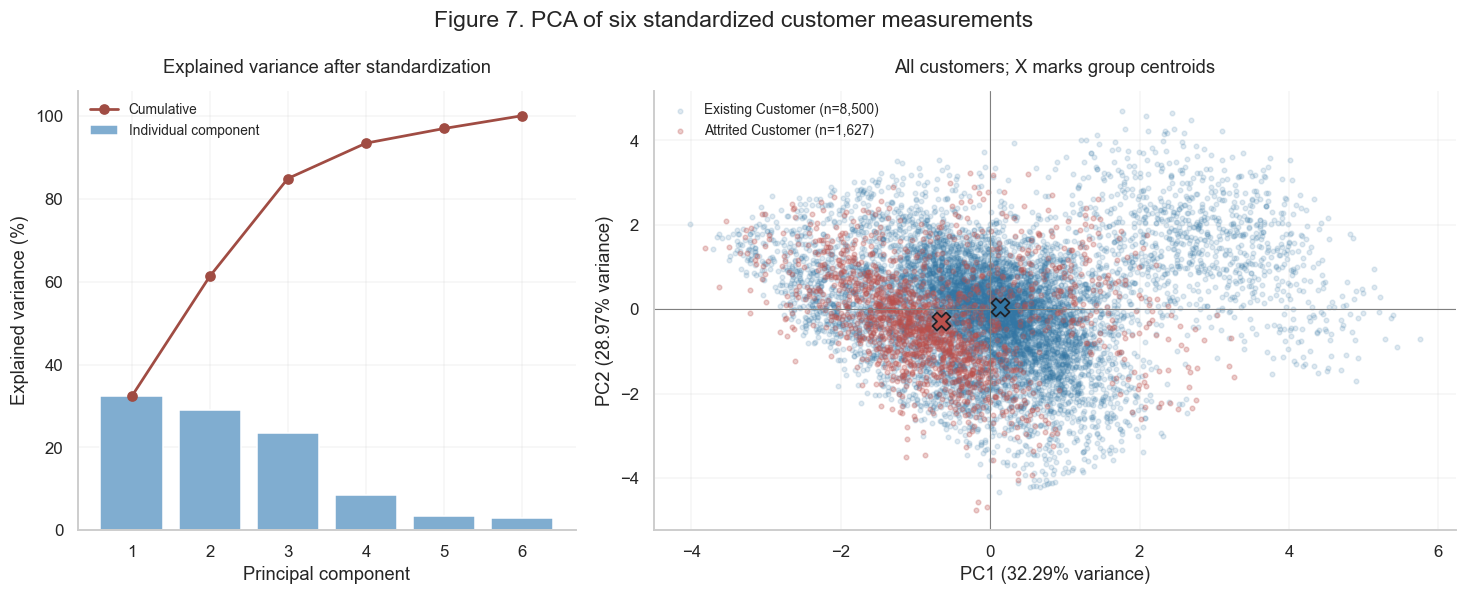

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), gridspec_kw={'width_ratios': [0.9, 1.45]})
positions = np.arange(1, len(numeric_columns) + 1)
axes[0].bar(positions, 100 * pca.explained_variance_ratio_, color='#80add0', label='Individual component')
axes[0].plot(positions, variance_table['Cumulative (%)'], '-o', color='#a04c43', lw=1.8,
             label='Cumulative')
axes[0].set(title='Explained variance after standardization', xlabel='Principal component',
            ylabel='Explained variance (%)', xticks=positions, ylim=(0, 106))
axes[0].legend(frameon=False, loc='upper left', fontsize=9)

for label in DRAW_ORDER:
    group = score_frame.loc[score_frame['Attrition_Flag'].eq(label)]
    axes[1].scatter(group['PC1'], group['PC2'], s=9, alpha=0.15 if label == 'Existing Customer' else 0.28,
                    color=STATUS_COLORS[label], rasterized=True, label=f'{label} (n={len(group):,})')
    axes[1].scatter(group['PC1'].mean(), group['PC2'].mean(), marker='X', s=140,
                    color=STATUS_COLORS[label], edgecolor='#20232a', linewidth=1.2, zorder=5)
axes[1].axhline(0, color='#808080', lw=0.7)
axes[1].axvline(0, color='#808080', lw=0.7)
axes[1].set(title='All customers; X marks group centroids',
            xlabel=f'PC1 ({100 * pca.explained_variance_ratio_[0]:.2f}% variance)',
            ylabel=f'PC2 ({100 * pca.explained_variance_ratio_[1]:.2f}% variance)')
axes[1].legend(frameon=False, fontsize=9, loc='upper left')
fig.suptitle('Figure 7. PCA of six standardized customer measurements', fontsize=15)
fig.tight_layout()
plt.show()

### 6.2 Interpretation and limits of the projection

**Explained variance.** PC1 explains **32.29%**, PC2 **28.97%**, and together **61.26%**. Therefore, **38.74%** of standardized variation is absent from the two-dimensional score plot. PC3 alone accounts for another **23.60%**; the first three components retain **84.86%**. The two-axis picture is useful but incomplete.

**Component meaning.** The displayed coefficients are weights in linear combinations of standardized variables, not causal effects or variable–component correlations. PC1 has strong positive weights for transaction count (**0.557**) and amount (**0.571**) and negative weights for age (**−0.380**) and tenure (**−0.370**). It contrasts activity with part of the life-cycle pattern rather than representing spending alone. PC2 emphasizes age (**0.589**) and tenure (**0.597**) while also including positive activity weights. PC3 helps describe the financial-capacity/utilization contrast, which is a reason not to ignore the omitted variation. Component signs can be reversed without changing a PCA solution.

**Status comparison.** In this fitted orientation, attrited customers have a lower PC1 centroid (**−0.664**) than existing customers (**0.127**), consistent with their lower transaction activity. Their PC2 centroids are about **−0.268** and **0.051**. The point clouds still overlap considerably. PCA maximizes overall variation and does not seek attrition separation; these centroids are descriptive and do not constitute a classifier, significance test, or evidence of distinct natural clusters.

The main limitations are the right-skewed monetary variables, repeated maximum credit limits, utilization zeros, correlated age and tenure, and the linear nature of PCA. Standardization alone does not make any of those features disappear.

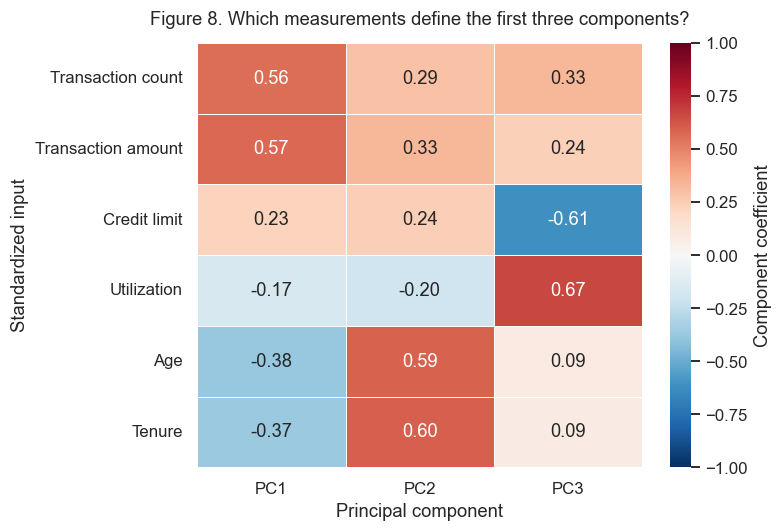

In [18]:
fig, ax = plt.subplots(figsize=(7.2, 5.0))
sns.heatmap(component_coefficients[['PC1', 'PC2', 'PC3']], annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=0.5,
            yticklabels=heat_labels, cbar_kws={'label': 'Component coefficient'}, ax=ax)
ax.set(title='Figure 8. Which measurements define the first three components?',
       xlabel='Principal component', ylabel='Standardized input')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
plt.show()

**Figure 8.** The coefficient heatmap makes the mixed meaning of the axes explicit. Activity and age/tenure contribute to both PC1 and PC2, whereas PC3 has large opposing weights for credit limit and utilization. Thus, the relatively weak limit–spending relation does not mean that financial measurements carry no multivariate information; much of their variation appears outside the first two axes.

In [19]:
# Sensitivity only: transform positive monetary variables, then re-standardize all inputs.
log_inputs = df[numeric_columns].copy()
log_inputs[['Credit_Limit', 'Total_Trans_Amt']] = np.log(
    log_inputs[['Credit_Limit', 'Total_Trans_Amt']]
)
log_standardized = StandardScaler().fit_transform(log_inputs)
log_pca = PCA(svd_solver='full').fit(log_standardized)

pca_sensitivity = pd.DataFrame({
    'Original variables, standardized': pca.explained_variance_ratio_,
    'Log monetary variables, then standardized': log_pca.explained_variance_ratio_
}, index=component_names).T
pca_sensitivity['PC1 + PC2'] = pca_sensitivity['PC1'] + pca_sensitivity['PC2']
pca_sensitivity['PC1 + PC2 + PC3'] = pca_sensitivity[['PC1', 'PC2', 'PC3']].sum(axis=1)
display((100 * pca_sensitivity[['PC1', 'PC2', 'PC3', 'PC1 + PC2', 'PC1 + PC2 + PC3']]).round(2))
print('Logged-analysis coefficients; monetary rows refer to their natural logarithms:')
display(pd.DataFrame(log_pca.components_[:2].T, index=numeric_columns, columns=['PC1', 'PC2']).round(4))

,PC1,PC2,PC3,PC1 + PC2,PC1 + PC2 + PC3
"Original variables, standardized",32.29,28.97,23.60,61.26,84.86
"Log monetary variables, then standardized",33.21,28.94,25.12,62.16,87.27


Logged-analysis coefficients; monetary rows refer to their natural logarithms:


,PC1,PC2
Total_Trans_Ct,0.6086,0.2935
Total_Trans_Amt,0.6117,0.3035
Credit_Limit,0.1550,0.1931
Avg_Utilization_Ratio,-0.1023,-0.1535
Customer_Age,-0.3382,0.6127
Months_on_book,-0.3265,0.6208


### 6.3 Transformation sensitivity

After logging credit limit and transaction amount and then standardizing, the first two components retain **62.16%**, compared with **61.26%** originally. In the displayed orientation, activity still contributes positively to PC1, and age/tenure contribute strongly to PC2. This supports a similar broad reading for this particular transformation, but does not prove robustness to all outliers or modelling choices.

The two fits use different feature scales and define different variance spaces. Their explained-variance percentages therefore cannot be read as prediction scores or proof that one representation is better. The raw standardized PCA remains the primary analysis so it corresponds directly to the original-variable heatmaps; the logged version documents the influence of a reasonable transformation without deleting customers.

## 7. Integrated interpretation

The clearest group difference is transaction activity by attrition status. Attrited customers have median annual spending of \$2,329 versus \$4,100 for existing customers, together with a much narrower central IQR. Means point in the same direction, but are raised by right tails in both groups. Retaining the plausible extreme customers and showing robust statistics preserves the earlier results without allowing high-value observations to determine the whole interpretation.

Across card categories, the largest observed median contrast is between Platinum and Blue, but Platinum contains only 20 customers. Blue accounts for over 93% of the file. Premium-card spending looks higher in this sample, yet unequal sample sizes, wide overlapping ranges, and customer selection into products limit how confidently that difference can be generalized. These are descriptive group differences, not effects of card upgrades.

Income stratification provides a more careful reading of Assignment 3's credit-limit–spending relationship. All income groups retain a modest positive linear correlation, but the rank correlations remain weak and the maximum-limit pile-up differs between groups. Income is a possible common influence; after removing its category means, the correlation increases only from 0.172 to 0.200. The pooled pattern therefore does not reverse, and a large limit remains an unreliable summary of typical spending.

The income–attrition chi-square test rejects exact independence at α = 0.05, but Cramér's V of 0.036 shows that the association is very weak. This reconciles a statistically significant result with the small, non-monotonic differences already observed in Assignment 1. Large samples can detect departures from independence that have limited practical importance.

The multivariate analysis adds structure: transaction count and amount share considerable information, as do age and tenure, while credit limit and utilization contribute a separate financial dimension. The first two PCA components summarize 61.26% of variation and show overlapping attrition groups; the third component is substantial. Thus, a two-dimensional display is a partial summary of heterogeneous customer behavior, not evidence of causes, reliable prediction, or sharply separated customer types.

### 7.1 Limitations

- **Sampling and timing:** the source file provides no demonstrated probability sample or time ordering sufficient for causal claims. Annual activity could be related to the process of attrition rather than precede it as a clean predictor.
- **Unequal groups:** attrition status is imbalanced, Blue dominates card categories, and the Platinum distribution is based on 20 customers. Descriptive contrasts do not automatically generalize.
- **Unknown categories:** keeping `Unknown` avoids inventing information, but does not resolve why income, education, or marital status is unreported. The known-income sensitivity subset may differ systematically.
- **Tails and boundaries:** monetary skewness, plausible high values, a pile-up at the maximum limit, and utilization zeros affect visualizations and linear summaries. Group-specific IQR flags are not error diagnoses.
- **Mathematical dependence and omitted factors:** amount/count, utilization/limit, and age/tenure are partly related by construction or life-cycle constraints. Income strata leave other influences unadjusted.
- **Inference and dimension reduction:** chi-square tests overall independence under assumptions; it does not identify causal effects or significant category pairs. PCA depends on variable and scale choices and loses 38.74% of variation in two dimensions.

### 7.2 New research questions

1. **Amount per transaction within comparable activity:** within narrow transaction-count bands, do attrited and existing customers differ in `Total_Trans_Amt / Total_Trans_Ct`? This would separate transaction frequency from typical transaction size, while recognizing that the ratio reuses the original measurements.
2. **Joint income and product composition:** does the modest within-income limit–spending association change after also separating Blue from premium cards? Would premium-group differences remain with enough observations in each income–card combination?
3. **Maximum-limit pile-up:** among customers with positive revolving balances, does the limit–utilization relationship differ between records at the maximum limit and records below it? Additional source information would be needed to distinguish an administrative ceiling from other recording mechanisms.
4. **Unreported income:** do unknown-income customers differ from known-income customers in card category, transaction activity, or recorded limit? Could the mechanism behind unreported income change the group comparisons?
5. **Beyond the first two PCs:** how much of the attrition overlap remains when PC3 is considered, or when less redundant feature sets and robust scaling are used? Any future predictive claim would require time-aware, held-out evaluation and a clear observation window.

These questions follow from the current results; they have not been tested in this assignment and are not presented as established findings.

## 8. Assignment requirements and reproducibility check

| Required output | Location in this notebook |
|---|---|
| Two group-comparison plots, including 3+ groups | Figure 1: attrition; Figure 2: four card categories, both using `Total_Trans_Amt` |
| Count, mean, median and IQR or SD | Section 1 and Section 2 summary tables include all of these |
| Stratified plot and confounding discussion | Figure 3, income-specific coefficients, and Sections 3.1–3.2 |
| Chi-square, df, p-value and Cramér's V | Section 4: observed/expected tables, manual formula checks, results, Figure 4 and interpretation |
| Pair plot or equivalent using at least four numerical variables | Figure 5: all six selected variables |
| Correlation heatmap and relationship interpretation | Figure 6: Pearson and Spearman; Section 5.1 |
| Standardized PCA, explained variance and interpretation | Figures 7–8, variance/coefficient tables and Sections 6.1–6.3 |
| Markdown beside major results | Interpretations immediately follow the relevant tables and figures |
| Main findings, new questions and limitations | Sections 7–7.2 |
| Reproducible organization | One CSV load, explicit column choices, deterministic calculations, environment versions, source checksum, and checks below |

No data are downloaded, no original CSV values are overwritten, and no earlier notebooks are needed as computational inputs.

In [20]:
# Final consistency checks for the submitted analysis.
assert status_summary['n'].sum() == len(df)
assert card_summary['n'].sum() == len(df)
assert observed.to_numpy().sum() == len(df)
assert income_relationships.loc[INCOME_ORDER, 'n'].sum() == len(df)
assert numeric_columns == list(component_coefficients.index)
assert standardized.shape == (len(df), 6)
assert scores.shape == (len(df), 6)
assert 0 <= cramers_v <= 1
assert np.all(np.isfinite(scores))
assert not set(numeric_columns).intersection(['CLIENTNUM', 'Attrition_Flag'] + classifier_cols)
print('All consistency checks passed.')
print(f'All {len(df):,} customers were retained in every primary analysis.')
print('The known-income subset and logged-variable PCA are explicitly marked sensitivity analyses.')

All consistency checks passed.
All 10,127 customers were retained in every primary analysis.
The known-income subset and logged-variable PCA are explicitly marked sensitivity analyses.
